<a href="https://colab.research.google.com/github/maya-marvin/AI-101-Assignment--1/blob/main/Copy_of_Assignment3a.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
import pandas as pd

df = pd.read_csv('/content/Hitters.csv')

print("File loaded successfully!")
display(df.head())

File loaded successfully!


,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,CAtBat,CHits,CHmRun,CRuns,CRBI,CWalks,League,Division,PutOuts,Assists,Errors,Salary,NewLeague
0,293,66,1,30,29,14,1,293,66,1,30,29,14,A,E,446,33,20,NaN,A
1,315,81,7,24,38,39,14,3449,835,69,321,414,375,N,W,632,43,10,475.0,N
2,479,130,18,66,72,76,3,1624,457,63,224,266,263,A,W,880,82,14,480.0,A
3,496,141,20,65,78,37,11,5628,1575,225,828,838,354,N,E,200,11,3,500.0,N
4,321,87,10,39,42,30,2,396,101,12,48,46,33,N,E,805,40,4,91.5,N


This code uses Pandas to load my data from assignment 2 which is Hitters.csv file and the displays the first five rows to make sure the data is loaded correctly

In [ ]:
# Show the number of rows and columns
print("Dataset Shape:", df.shape)

# Show column names, data types, and missing values
print("\nDataset Info:")
print(df.info())

# Show descriptive statistics
print("\nDescriptive Statistics:")
print(df.describe())

Dataset Shape: (322, 20)

Dataset Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 322 entries, 0 to 321
Data columns (total 20 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   AtBat      322 non-null    int64  
 1   Hits       322 non-null    int64  
 2   HmRun      322 non-null    int64  
 3   Runs       322 non-null    int64  
 4   RBI        322 non-null    int64  
 5   Walks      322 non-null    int64  
 6   Years      322 non-null    int64  
 7   CAtBat     322 non-null    int64  
 8   CHits      322 non-null    int64  
 9   CHmRun     322 non-null    int64  
 10  CRuns      322 non-null    int64  
 11  CRBI       322 non-null    int64  
 12  CWalks     322 non-null    int64  
 13  League     322 non-null    object 
 14  Division   322 non-null    object 
 15  PutOuts    322 non-null    int64  
 16  Assists    322 non-null    int64  
 17  Errors     322 non-null    int64  
 18  Salary     263 non-null    float64
 19  NewLeague 

This code gives info about my dataset. It shows that there are 322 rows and 20 columns. It also checks for missing values and shows the averages, minimums, and maximums

In [ ]:
# Calculate the original number of rows
original_rows = df.shape[0]

# Drop rows with any missing values
df_cleaned = df.dropna()

# Calculate the remaining and removed rows
remaining_rows = df_cleaned.shape[0]
removed_rows = original_rows - remaining_rows

# Print the results
print(f"Original rows in the dataset: {original_rows}")
print(f"Rows removed: {removed_rows}")
print(f"Remaining rows after cleaning: {remaining_rows}")

# Assign the cleaned DataFrame back to df if you want to update it
df = df_cleaned

Original rows in the dataset: 322
Rows removed: 59
Remaining rows after cleaning: 263


This code cleaned my dataset by removing rows with missing info. It started with 322 and removed 59 and left 263 so that my data was ready to use for analysis

In [ ]:
# Define the feature columns and the target variable
features = ['AtBat', 'Hits', 'HmRun', 'Runs', 'RBI', 'Walks', 'Years']
target = 'Salary'

X = df[features]
y = df[target]

# Split the dataset into 80% training data and 20% testing data
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred = model.predict(X_test)

# Evaluate the model's performance
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display the results clearly
print("=== Linear Regression Model Evaluation ===")
print(f"Mean Squared Error (MSE): {mse:.2f}")
print(f"R-squared (R2 Score):     {r2:.4f}")

=== Linear Regression Model Evaluation ===
Mean Squared Error (MSE): 169843.37
R-squared (R2 Score):     0.0610


This code creates a linear regression model to predict baseball player salaries based on their stats

In [ ]:
# Generate 100 random records by sampling with replacement
random_data = df[features].sample(n=100, replace=True, random_state=42).reset_index(drop=True)

# Display the first 10 rows
random_data.head(10)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years
0,445,99,1,46,24,29,4
1,343,103,6,48,36,40,15
2,511,138,25,76,96,61,3
3,237,52,0,15,25,30,24
4,629,168,18,73,102,40,18
5,445,99,1,46,24,29,4
6,399,102,3,56,34,34,5
7,382,101,16,50,55,22,1
8,283,77,14,45,47,26,16
9,306,104,14,50,58,25,7


This code creates 100 random baseball player records using info from my cleaned dataset

In [ ]:
# Make predictions on the random_data using the trained linear regression model
predictions = model.predict(random_data[features])

# Create a copy of the random_data features and add the predicted salaries
predicted_dataset = random_data[features].copy()
predicted_dataset['predicted_salary'] = predictions

# Display the first 10 rows of the new dataframe
predicted_dataset.head(10)

,AtBat,Hits,HmRun,Runs,RBI,Walks,Years,predicted_salary
0,445,99,1,46,24,29,4,155.611384
1,343,103,6,48,36,40,15,840.943957
2,511,138,25,76,96,61,3,655.111063
3,237,52,0,15,25,30,24,852.013198
4,629,168,18,73,102,40,18,1126.957305
5,445,99,1,46,24,29,4,155.611384
6,399,102,3,56,34,34,5,327.622760
7,382,101,16,50,55,22,1,234.401562
8,283,77,14,45,47,26,16,735.587596
9,306,104,14,50,58,25,7,611.790178


This code uses my trained linear regression model to predict salaries for the 100 baseball player records i generated

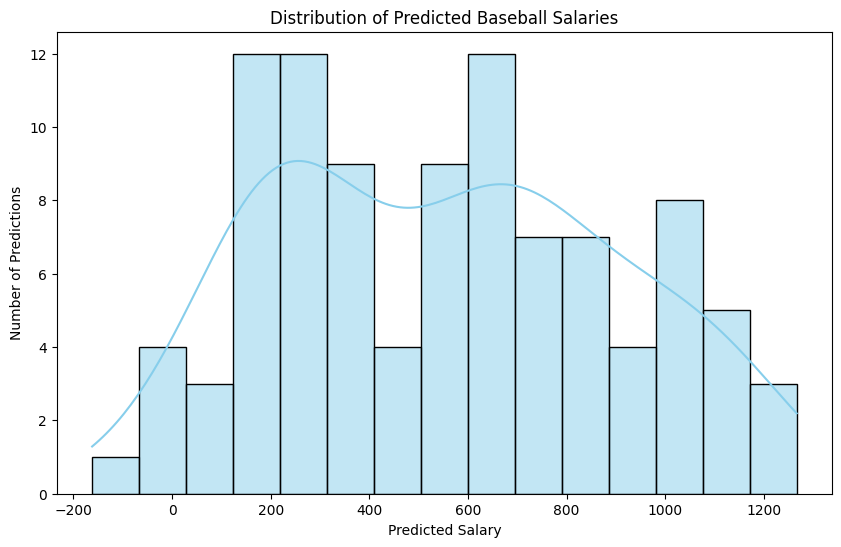

In [ ]:
# This code creates a histogram with a density curve using seaborn and matplotlib to show the distribution of 100 predicted baseball player salaries.
plt.figure(figsize=(10, 6))
sns.histplot(predicted_dataset['predicted_salary'], kde=True, color='skyblue', bins=15)

# Adding titles and labels
plt.title('Distribution of Predicted Baseball Salaries')
plt.xlabel('Predicted Salary')
plt.ylabel('Number of Predictions')

# Display the plot
plt.show()

This code created a histogram showing the distibution of the 100 predicted baseball salaries

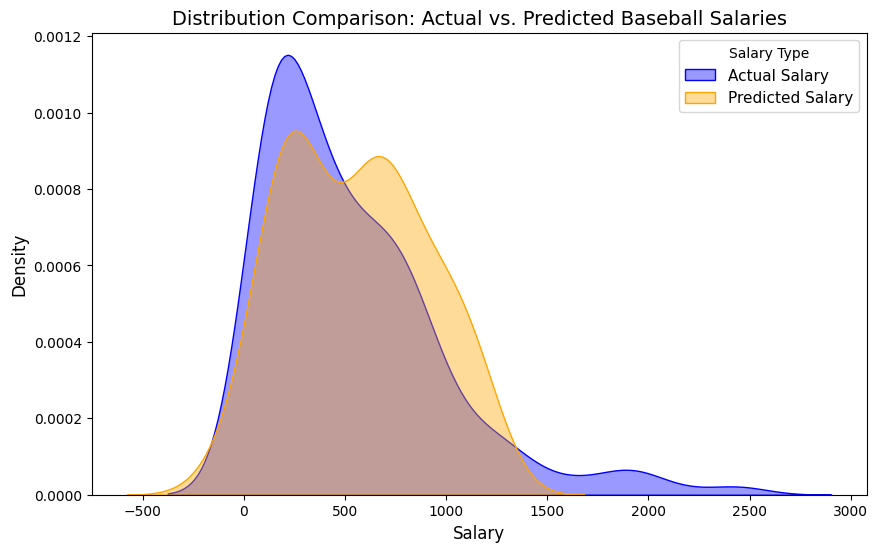

In [ ]:
# Import necessary libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size for the plot
plt.figure(figsize=(10, 6))

# Plot the actual salaries KDE curve
sns.kdeplot(data=df['Salary'], fill=True, color='blue', label='Actual Salary', alpha=0.4)

# Plot the predicted salaries KDE curve
sns.kdeplot(data=predicted_dataset['predicted_salary'], fill=True, color='orange', label='Predicted Salary', alpha=0.4)

# Adding labels and styling to the plot
plt.title('Distribution Comparison: Actual vs. Predicted Baseball Salaries', fontsize=14)
plt.xlabel('Salary', fontsize=12)
plt.ylabel('Density', fontsize=12)
plt.legend(title='Salary Type', fontsize=11)

# Display the plot
plt.show()

This code created a graph comparing the actual baseball salaries from my original dataset with salries predicted by my machine learning model